## Задача 1: Оценить месячный retention в оформление заказа с помощью когортного анализа

В ходе выполнения задачи нужно:
1. Исследовать датасет и определить, какой вид заказа будет учитываться в retention
2. Построить месячный retention
3. Проанализировать, чему равен медианный retention 1-го месяца (т.е. взять retention 1-ого месяца для всех когорт и посчитать по этим числам медиану)
4. Найти когорту с самым высоким retention на 3-й месяц.
5. Проиллюстрировать результаты релевантной визуализацией, удобной для восприятия.

### 1. Исследование датасета

In [1]:
import pandas as pd
from operator import attrgetter
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import colors as mcolors
import numpy as np

pd.options.mode.chained_assignment = None  # default='warn'

#### 1.1 Таблица orders

Описание колонок и значения статусов заказов:
- order_id — уникальный идентификатор заказа (номер чека)
- customer_id — позаказный идентификатор пользователя
- order_status — статус заказа
- order_purchase_timestamp — время создания заказа
- order_approved_at — время подтверждения оплаты заказа
- order_delivered_carrier_date — время передачи заказа в логистическую службу
- order_delivered_customer_date — время доставки заказа
- order_estimated_delivery_date — обещанная дата доставки

Статусы:
- created — создан
- invoiced — выставлен счёт (и ожидается оплата по нему)
- approved — подтверждён (подтверждена оплата)
- processing — в процессе сборки заказа
- shipped — отгружен со склада
- delivered — доставлен пользователю
- unavailable — недоступен (заказ не выполнен самим магазином; возможно, по причине отсутствия товаров заказа на складе)
- canceled — отменён пользователем

In [2]:
df_orders = pd.read_csv('olist_orders_dataset.csv', parse_dates=['order_purchase_timestamp',
                                                              'order_approved_at',
                                                              'order_delivered_carrier_date',
                                                              'order_delivered_customer_date',
                                                              'order_estimated_delivery_date'])
print(df_orders.shape)
df_orders.head()

(99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [3]:
# Типы данных в таблице, пропуски. Убедились, что даты преобразованы в datetime

df_orders.info()    

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [4]:
df_orders.isnull().sum()   

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

У всех заказов есть статус order_status

- У 160 заказов нет order_approved_at - времени оплаты заказа. 
- У 1783 заказов нет order_delivered_carrier_date - времени передачи заказа в логистическую службу
- У 2965 заказов нет order_delivered_customer_date - времени доставки заказа

In [5]:
# Создадим копию данных, чтобы избежать изменений в исходном датафрейме

orders = df_orders.copy()

In [6]:
# Посмотрим на период времени, который охватывает таблица

# Дата создания самого раннего заказа
print(orders.order_purchase_timestamp.min()) 

# Дата создания самого позднего заказа
print(orders.order_purchase_timestamp.max())

2016-09-04 21:15:19
2018-10-17 17:30:18


In [7]:
# Проверяем наличие дубликатов по order_id (уникальный идентификатор заказа)

orders_duplicated = orders['order_id'].duplicated()
orders_duplicated.sum()

# 0 - дубликатов нет

np.int64(0)

In [8]:
count_by_status = orders.groupby('order_status').agg(count=('order_id', 'nunique'))

# Доля заказов со статусом от общего числа заказов
count_by_status["rate"] = count_by_status["count"].apply(lambda x: x * 100/ 99441)      
count_by_status

,count,rate
order_status,,
approved,2,0.002011
canceled,625,0.628513
created,5,0.005028
delivered,96478,97.020344
invoiced,314,0.315765
processing,301,0.302692
shipped,1107,1.113223
unavailable,609,0.612423


Посмотрим на распределение заказов по статусам. 
 
Всего заказов - **99441**, доставленных - **97%** 
Исходя из распределения статусов заказов и их кол-ва можно предположить, что в таблице указан ПОСЛЕДНИЙ ИЗВЕСТНЫЙ статус заказа. 

По логике "заказ оформлен" означает, что заказ прошел этап оплаты. Клиент оплатой подтверил намерение купить товар. Посмотрим на время оплаты заказа и статус approved 

Выше мы получали, что у 160 заказов нет времени оплаты заказа

In [9]:
#not_paid = orders[orders['order_approved_at'].isnull()]
not_paid =  orders.query('order_approved_at.isna()')
not_paid.shape

(160, 8)

In [10]:
not_paid.groupby('order_status').agg(count=('order_id', 'nunique'))

,count
order_status,
canceled,141
created,5
delivered,14


Большинство неоплаченных заказов - это отмененные заказы. То есть их отменили до оплаты. Странно, что среди них еще есть доставленные. Мб это какие-то маркетинговые доставки, то есть пользователь их не совершал

In [11]:
# Посмотрим на оплаченные заказы
paid =  orders.query('order_approved_at.isna() == False')
paid.shape

(99281, 8)

In [12]:
paid.groupby('order_status').agg(count=('order_id', 'nunique'))

,count
order_status,
approved,2
canceled,484
delivered,96464
invoiced,314
processing,301
shipped,1107
unavailable,609


order_approved_at - время подтвеждения оплаты заказа, то есть после нее заказ переходит в approved

Но видим, что 314 значений иметю статус "выставлен счет", хотя факт оплаты есть. Скорее всего произошел технический сбой, и статус не поменялся на approved (не синхронизировались статусы).

484 заказа пользователь отменил ПОСЛЕ оплаты. 

Если человек отменил заказ, это равносильно тому, что он ему не нужен, и можно считать, что он его и "не оформлял".

Unavailable заказы пользователь намеривался купить и оплатил (так как есть дата оплаты), но потом их отменил магазин. Если рассматривать поведние пользователя, то факт оплаты подтвержает намерение купить товар, то есть совершение заказа. Но с другой стороны у пользователя нет положительного опыта покупки, и у магазина нет денег за такой заказ.

#### 1.2 Таблица customers
Таблица с уникальными идентификаторами пользователей. Описание колонок:
- customer_id — позаказный идентификатор пользователя
- customer_unique_id — уникальный идентификатор пользователя (аналог номера паспорта)
- customer_zip_code_prefix — почтовый индекс пользователя
- customer_city — город доставки пользователя
- customer_state — штат доставки пользователя


In [13]:
df_customers = pd.read_csv('olist_customers_dataset.csv')
customers = df_customers.copy()
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [14]:
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [15]:
# Проверяем наличие дубликатов по customer_id

customers_duplicated = customers['customer_id'].duplicated()
customers_duplicated.sum()

# 0 - дубликатов нет

np.int64(0)

In [16]:
customers.groupby('customer_unique_id').agg(count=('customer_id','nunique')).sort_values('count', ascending=False)

,count
customer_unique_id,
8d50f5eadf50201ccdcedfb9e2ac8455,17
3e43e6105506432c953e165fb2acf44c,9
6469f99c1f9dfae7733b25662e7f1782,7
ca77025e7201e3b30c44b472ff346268,7
1b6c7548a2a1f9037c1fd3ddfed95f33,7
...,...
5657dfebff5868c4dc7e8355fea865c4,1
5657596addb4d7b07b32cd330614bdf8,1
5656eb169546146caeab56c3ffc3d268,1


Отметим, что некоторым customer_unique_id соотвествует больше чем 1 customer_id.
Значит, чтобы понять, какой пользователь вернулся за потворным заказом, нужно учитывать именно **customer_unique_id** (у пользователя мб несколько "аккаунтов")

#### 1.3 Таблица items
Таблица с товарными позициями, входящими в заказы. Описание колонок:
- order_id — уникальный идентификатор заказа (номер чека)
- order_item_id — идентификатор товара внутри одного заказа
- product_id — ид товара (аналог штрихкода)
- seller_id — ид производителя товара
- shipping_limit_date — максимальная дата доставки продавцом для передачи заказа партнеру по логистике
- price — цена за единицу товара
- freight_value — вес товара 

In [17]:
df_items = pd.read_csv('olist_order_items_dataset.csv', parse_dates = ['shipping_limit_date'])
items = df_items.copy()
items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [18]:
items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [19]:
items.shape

(112650, 7)

In [20]:
items_nonduplicated = items.drop_duplicates(subset=['order_id', 'product_id', 'order_item_id'])
items_nonduplicated.shape

# размеры items и items_nonduplicated совпадают => дубликатов нет

(112650, 7)

#### 1.4 Корреляция таблиц customers , items и orders

1. Для вычисления retention будем смотреть на customer_unique_id пользователя, следовательно, нужно смержить customers и orders по полю customer_id

In [21]:
orders_with_customers = orders.merge(right=customers, how='left', on='customer_id')
print(orders_with_customers.shape)
print(orders.shape)
orders_with_customers.head()

(99441, 12)
(99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [22]:
orders_with_customers.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
dtype: int64

 У всех customer_id есть customer_unique_id

In [23]:
n1 = orders_with_customers.order_id.nunique()   # уникальные заказы в orders
print(n1)

99441


In [24]:
n2 = items.order_id.nunique()   # уникальные заказы в items
print(n2)

98666


In [25]:
print(n1 - n2)

775


Видим, что в таблице orders на 775 заказов больше, чем в таблице items, в которой расписаны покупки в заказах.
Посмотрим поближе на заказы, которые есть в orders, но нет в items

In [26]:
orders_not_in_items = orders_with_customers[~orders_with_customers.order_id.isin(items.order_id)]
orders_not_in_items.shape

(775, 12)

In [27]:
orders_not_in_items.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
266,8e24261a7e58791d10cb1bf9da94df5c,64a254d30eed42cd0e6c36dddb88adf0,unavailable,2017-11-16 15:09:28,2017-11-16 15:26:57,NaT,NaT,2017-12-05,41fc647b8c6bd979b1b6364b60471b50,89288,sao bento do sul,SC
586,c272bcd21c287498b4883c7512019702,9582c5bbecc65eb568e2c1d839b5cba1,unavailable,2018-01-31 11:31:37,2018-01-31 14:23:50,NaT,NaT,2018-02-16,0e634b16e4c585acbd7b2e8276ce6677,11701,praia grande,SP
687,37553832a3a89c9b2db59701c357ca67,7607cd563696c27ede287e515812d528,unavailable,2017-08-14 17:38:02,2017-08-17 00:15:18,NaT,NaT,2017-09-05,596ed6d7a35890b3fbac54ec01f69685,2318,sao paulo,SP
737,d57e15fb07fd180f06ab3926b39edcd2,470b93b3f1cde85550fc74cd3a476c78,unavailable,2018-01-08 19:39:03,2018-01-09 07:26:08,NaT,NaT,2018-02-06,2349bbb558908e0955e98d47dacb7adb,48607,paulo afonso,BA
1130,00b1cb0320190ca0daa2c88b35206009,3532ba38a3fd242259a514ac2b6ae6b6,canceled,2018-08-28 15:26:39,NaT,NaT,NaT,2018-09-12,4fa4365000c7090fcb8cad5713c6d3db,1151,sao paulo,SP


In [28]:
orders_not_in_items.groupby('order_status').agg(count=('order_id', 'nunique'))

,count
order_status,
canceled,164
created,5
invoiced,2
shipped,1
unavailable,603


В основном заказы из orders, которых нет в items - это отмененные и недоступные заказы. 
Видим, что только 3 из них по статусам прошли оплату и есть дата подтверждения. Также среди них нет ни одного доставленного заказа. 5 только созданы и без оплаты.

In [29]:
orders_not_in_items.query('order_status in ["invoiced", "shipped", "created"]')

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
7434,b5359909123fa03c50bdb0cfed07f098,438449d4af8980d107bf04571413a8e7,created,2017-12-05 01:07:52,NaT,NaT,NaT,2018-01-11,55fbb57fd54c35a38c80c2a032a6ca6e,15300,general salgado,SP
9238,dba5062fbda3af4fb6c33b1e040ca38f,964a6df3d9bdf60fe3e7b8bb69ed893a,created,2018-02-09 17:21:04,NaT,NaT,NaT,2018-03-07,2e015e68fbfa36910263df5384e8e45c,73401,brasilia,DF
21441,7a4df5d8cff4090e541401a20a22bb80,725e9c75605414b21fd8c8d5a1c2f1d6,created,2017-11-25 11:10:33,NaT,NaT,NaT,2017-12-12,355862aa14375fe3950ee04fef9c7a53,22621,rio de janeiro,RJ
23254,a68ce1686d536ca72bd2dadc4b8671e5,d7bed5fac093a4136216072abaf599d5,shipped,2016-10-05 01:47:40,2016-10-07 03:11:22,2016-11-07 16:37:37,NaT,2016-12-01,f15a952dfc52308d0361288fbf42c7b3,91250,porto alegre,RS
55086,35de4050331c6c644cddc86f4f2d0d64,4ee64f4bfc542546f422da0aeb462853,created,2017-12-05 01:07:58,NaT,NaT,NaT,2018-01-08,10d5890ed5e7ec78a7db23b5ac579b17,93025,sao leopoldo,RS
57591,2ce9683175cdab7d1c95bcbb3e36f478,b2d7ae0415dbbca535b5f7b38056dd1f,invoiced,2016-10-05 21:03:33,2016-10-06 07:46:39,NaT,NaT,2016-11-25,6a2da481aa7827b951175772a0fe8bb8,16012,aracatuba,SP
58958,90ab3e7d52544ec7bc3363c82689965f,7d61b9f4f216052ba664f22e9c504ef1,created,2017-11-06 13:12:34,NaT,NaT,NaT,2017-12-01,161e5b2b4513edb336986a8909218365,87720,paranavai,PR
69926,e04f1da1f48bf2bbffcf57b9824f76e1,0d00d77134cae4c58695086ad8d85100,invoiced,2016-10-05 13:22:20,2016-10-06 15:51:38,NaT,NaT,2016-11-29,8886115442775dd8a20c2dcc921c7cc8,88070,florianopolis,SC


 #### 1.5 Что такое совершенный заказ
 
Общие мысли на тему Retention в оформление заказа. 
Думаю, стоит разделять оформление заказа-намерение и в оформление заказа как законченный процесс.
Оформление - намерение купить товар, подкрепленное оплатой. Клиент ждет заказ. И при этом он сам не хочет его отменять. Пользователя "зацепил" товар. Если товар не будет доставлен по какой-то причине (его не на складе/проблемы при доставке), то это не влият на сам факт оформления. 

На этапе доставка могут быть какие-то логистические проблемы => такой ретеншт будет еще частично отражать и работу логистики.

Подводя итого, в Retention в офомление заказа я бы учитывала заказы, которые:
- пользователь оплатил (есть время подтверждения оплаты order_approved_at)
- и при этом сам его не отменил (нет статуса cancelled)

Для денежных метрик, которые будем считать в других заданиях, я бы учитывала только оплаченные и ДОСТАВЛЕННЫЕ заказы, так как именно доставленные заказы уже считаются завершенными. А по потерянным заказам/недоступны могли вернуть деньги обратно, что не отражено в таблице.

In [30]:
paid_merged = orders_with_customers.query('order_approved_at.isna() == False')
paid_merged.shape

(99281, 12)

In [31]:
# Оплаченные и не отмененные заказы
paid_non_canceled_orders = paid_merged.query('order_status != "canceled"')
paid_non_canceled_orders.shape  # 98797 заказов

(98797, 12)

In [32]:
# Оплаченные и доставленные заказы
paid_delivered_orders =  paid_merged.query('order_status == "delivered"')
paid_delivered_orders.shape

(96464, 12)

### 2. Построить месячный Retention

Cтроим когорты по месяцу: для каждого заказа извлекаем месяц и день создания заказа, а затем присваиваем когорты на основе даты первого заказа для каждого пользователя (месяц первой покупки).

In [33]:
# оставим только нужные поля в таблице
data = paid_non_canceled_orders.copy()[["order_id",	"order_purchase_timestamp", "order_approved_at", "customer_unique_id"]]

# Извлекаем месяц и день заказа
data['order_purchase_month'] = data['order_purchase_timestamp'].dt.to_period('M')
data['order_purchase_day'] = data['order_purchase_timestamp'].dt.to_period('D')
data.head()

,order_id,order_purchase_timestamp,order_approved_at,customer_unique_id,order_purchase_month,order_purchase_day
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-02 11:07:15,7c396fd4830fd04220f754e42b4e5bff,2017-10,2017-10-02
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-07-26 03:24:27,af07308b275d755c9edb36a90c618231,2018-07,2018-07-24
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-08 08:55:23,3a653a41f6f9fc3d2a113cf8398680e8,2018-08,2018-08-08
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-11-18 19:45:59,7c142cf63193a1473d2e66489a9ae977,2017-11,2017-11-18
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-13 22:20:29,72632f0f9dd73dfee390c9b22eb56dd6,2018-02,2018-02-13


In [34]:
# Присваиваем когорты на основе даты первого заказа для каждого пользователя

data['cohort'] = data.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')
data['cohort_day'] = data.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('D')

In [35]:
# Рассчитываем номер периода в днях (месячные периоды, деля на 30) - 
# 0, 1, 2 … месяцев после первой покупки. О - месяц первой покупки

# способ 1
data['period_number_month'] = np.floor((data.order_purchase_day - data.cohort_day).apply(attrgetter('n')) / 30)

# cпособ 2
data['cohort_period'] = data.order_purchase_month.astype(int) - data.cohort.astype(int)

ПРИМЕЧАНИЕ. Если считать когорты как в лекции (колонка period_number_month), то получаются одни значения ретенш матрицы, если спобов 2 - то другие. 

Например, данные не совпадают для коргты 2017-10-02

Эти различия могут влиять на задания 2-3, поэтому в этих заданиях напишу два варинта. 
В дргуих заданиях буду учитывать только способ 1

In [36]:
data[["order_purchase_timestamp", "cohort_day", "cohort", "period_number_month", "cohort_period"]].head(20)

,order_purchase_timestamp,cohort_day,cohort,period_number_month,cohort_period
0,2017-10-02 10:56:33,2017-09-04,2017-09,0.0,1
1,2018-07-24 20:41:37,2018-07-24,2018-07,0.0,0
2,2018-08-08 08:38:49,2018-08-08,2018-08,0.0,0
3,2017-11-18 19:28:06,2017-11-18,2017-11,0.0,0
4,2018-02-13 21:18:39,2018-02-13,2018-02,0.0,0
5,2017-07-09 21:57:05,2017-07-09,2017-07,0.0,0
6,2017-04-11 12:22:08,2017-04-11,2017-04,0.0,0
7,2017-05-16 13:10:30,2017-05-16,2017-05,0.0,0
8,2017-01-23 18:29:09,2017-01-23,2017-01,0.0,0
9,2017-07-29 11:55:02,2017-07-29,2017-07,0.0,0


In [37]:
data.shape

(98797, 10)

In [38]:
data.query('period_number_month > 0')

,order_id,order_purchase_timestamp,order_approved_at,customer_unique_id,order_purchase_month,order_purchase_day,cohort,cohort_day,period_number_month,cohort_period
15,dcb36b511fcac050b97cd5c05de84dc3,2018-06-07 19:03:12,2018-06-12 23:31:02,ccafc1c3f270410521c3c6f3b249870f,2018-06,2018-06-07,2016-10,2016-10-06,20.0,20
16,403b97836b0c04a622354cf531062e5f,2018-01-02 19:00:43,2018-01-02 19:09:04,6e26bbeaa107ec34112c64e1ee31c0f5,2018-01,2018-01-02,2017-07,2017-07-04,6.0,6
72,6abaad69b8b349c3a529b4b91ce18e46,2018-02-15 10:33:30,2018-02-15 10:47:59,fa0ee7ceb94193fb02aa78ce3a55695a,2018-02,2018-02-15,2018-01,2018-01-01,1.0,1
148,95cf9f239f724799131f7ca949209bd9,2018-05-25 08:54:21,2018-05-25 09:16:24,65ee274b862c5c053367be8a70dbc029,2018-05,2018-05-25,2018-04,2018-04-25,1.0,1
186,5487a8ac1699754d975f853ce8bb9321,2018-03-29 14:29:44,2018-04-03 05:48:50,995fe9426f030109b1614044edaf46d9,2018-03,2018-03-29,2017-10,2017-10-04,5.0,5
...,...,...,...,...,...,...,...,...,...,...
99167,ad005b5bdc8ec1f3085f0967211207d1,2018-08-05 10:50:43,2018-08-05 11:05:07,9b7fcde05dd369caf4dea1f04ed39fcc,2018-08,2018-08-05,2017-09,2017-09-15,10.0,11
99211,b5d08e6b71d4af8f816daf169014c908,2017-12-04 09:56:29,2017-12-05 10:03:30,439624e26bc73309799fd718773bdb8a,2017-12,2017-12-04,2017-08,2017-08-03,4.0,4
99223,843f956709f0a664d816bee124544122,2018-06-09 21:51:46,2018-06-09 22:19:06,f0a8e36658d6d08f6e96b9ecf389fd52,2018-06,2018-06-09,2018-05,2018-05-03,1.0,1
99344,bfecb4ee6ab98bff69307aab578db48a,2018-03-17 12:52:37,2018-03-17 13:10:35,dca9a13536adcef18c6c5859487347b1,2018-03,2018-03-17,2017-12,2017-12-26,2.0,3


In [39]:
# Агрегируем данные по когортам и рассчитанному номеру периода (в месяцах)

data_cohort = data.groupby(['cohort', 'period_number_month']).agg(n_customers=('customer_unique_id', 'nunique')).reset_index()
data_cohort.head(30)

,cohort,period_number_month,n_customers
0,2016-09,0.0,2
1,2016-10,0.0,297
2,2016-10,6.0,1
3,2016-10,9.0,1
4,2016-10,11.0,1
5,2016-10,13.0,1
6,2016-10,15.0,1
7,2016-10,17.0,1
8,2016-10,19.0,2
9,2016-10,20.0,1


In [40]:
data_cohort.cohort.nunique()

23

In [41]:
# Создаем сводную таблицу для когортного анализа
cohort_pivot = data_cohort.pivot_table(index='cohort', columns='period_number_month', values='n_customers')

In [42]:
cohort_pivot.head()

period_number_month,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,19.0,20.0,21.0
cohort,,,,,,,,,,,,,,,,,,,,,
2016-09,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,297.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,...,1.0,NaN,1.0,NaN,1.0,NaN,1.0,2.0,1.0,1.0
2016-12,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,760.0,2.0,NaN,4.0,1.0,1.0,3.0,2.0,NaN,NaN,...,5.0,3.0,2.0,NaN,2.0,2.0,2.0,1.0,NaN,NaN
2017-02,1723.0,3.0,3.0,6.0,4.0,2.0,4.0,2.0,1.0,5.0,...,6.0,2.0,3.0,2.0,1.0,2.0,4.0,NaN,NaN,NaN


In [43]:
# Рассчитываем размеры когорт (первый столбец сводной таблицы)
cohort_size = cohort_pivot.iloc[:, 0]
cohort_size

cohort
2016-09       2.0
2016-10     297.0
2016-12       1.0
2017-01     760.0
2017-02    1723.0
2017-03    2603.0
2017-04    2334.0
2017-05    3571.0
2017-06    3126.0
2017-07    3868.0
2017-08    4162.0
2017-09    4112.0
2017-10    4447.0
2017-11    7268.0
2017-12    5477.0
2018-01    6992.0
2018-02    6382.0
2018-03    6946.0
2018-04    6700.0
2018-05    6600.0
2018-06    5923.0
2018-07    6034.0
2018-08    6215.0
Freq: M, Name: 0.0, dtype: float64

In [44]:
# Вычисляем коэффициенты удержания, деля на размер когорты
retention_matrix = cohort_pivot.divide(cohort_size, axis=0)
retention_matrix.shape

(23, 21)

In [45]:
# В итоге матрица retention по месяцам (столбец - месяц, начинается с 0):
retention_matrix.head(23)

period_number_month,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,19.0,20.0,21.0
cohort,,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,1.0,NaN,NaN,NaN,NaN,NaN,0.003367,NaN,NaN,0.003367,...,0.003367,NaN,0.003367,NaN,0.003367,NaN,0.003367,0.006734,0.003367,0.003367
2016-12,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,1.0,0.002632,NaN,0.005263,0.001316,0.001316,0.003947,0.002632,NaN,NaN,...,0.006579,0.003947,0.002632,NaN,0.002632,0.002632,0.002632,0.001316,NaN,NaN
2017-02,1.0,0.001741,0.001741,0.003482,0.002322,0.001161,0.002322,0.001161,0.000580,0.002902,...,0.003482,0.001161,0.001741,0.001161,0.000580,0.001161,0.002322,NaN,NaN,NaN
2017-03,1.0,0.002689,0.004994,0.004226,0.001153,0.000768,0.003458,0.001537,0.002689,0.002305,...,0.001921,0.001921,0.001153,0.002689,0.000768,0.001153,0.001153,NaN,NaN,NaN
2017-04,1.0,0.003428,0.002571,0.000428,0.002999,0.003428,0.002571,0.004284,0.002142,0.002571,...,0.001714,NaN,0.000857,0.000857,0.000857,0.001285,NaN,NaN,NaN,NaN
2017-05,1.0,0.004481,0.004201,0.003360,0.003640,0.003360,0.003360,0.001400,0.003080,0.002520,...,0.003080,0.001960,0.001120,0.002240,0.001400,NaN,NaN,NaN,NaN,NaN
2017-06,1.0,0.003839,0.004479,0.003839,0.001280,0.005118,0.002879,0.001919,0.001280,0.003519,...,0.002559,0.000640,0.002559,0.000960,NaN,NaN,NaN,NaN,NaN,NaN


Заметим, что не хватает когорты 2016-11. И почти все данные по когортам 2016-09 - 2016-12 равны NaN, то есть пользователи совершили первую покупки и дальше практически не возвращались.

### 3. Медианный retention 1-го месяца

In [46]:
retention_matrix.describe()

period_number_month,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,19.0,20.0,21.0
count,23.0,19.000000,17.000000,17.000000,16.000000,15.000000,15.000000,13.000000,11.000000,11.000000,...,10.000000,7.000000,8.000000,5.000000,6.000000,4.000000,4.000000,2.000000,1.000000,1.000000
mean,1.0,0.003665,0.002868,0.002725,0.002310,0.002203,0.002510,0.002038,0.001850,0.002380,...,0.002721,0.001737,0.001905,0.001581,0.001601,0.001558,0.002368,0.004025,0.003367,0.003367
std,0.0,0.001308,0.001268,0.001282,0.000966,0.001380,0.000914,0.001022,0.000959,0.000891,...,0.001664,0.001121,0.000879,0.000829,0.001141,0.000719,0.000921,0.003831,NaN,NaN
min,1.0,0.000994,0.000899,0.000428,0.000896,0.000432,0.000913,0.000858,0.000580,0.000275,...,0.000243,0.000640,0.000857,0.000857,0.000580,0.001153,0.001153,0.001316,0.003367,0.003367
25%,1.0,0.002900,0.001741,0.002191,0.001509,0.001333,0.002362,0.001400,0.001279,0.002097,...,0.001766,0.000941,0.001144,0.000960,0.000790,0.001159,0.002029,0.002670,0.003367,0.003367
50%,1.0,0.003619,0.002614,0.002820,0.002336,0.001859,0.002585,0.001810,0.001442,0.002520,...,0.002572,0.001810,0.001775,0.001161,0.001129,0.001223,0.002477,0.004025,0.003367,0.003367
75%,1.0,0.004256,0.003604,0.003482,0.003025,0.002775,0.003120,0.002403,0.002581,0.002873,...,0.003295,0.001941,0.002577,0.002240,0.002324,0.001622,0.002815,0.005379,0.003367,0.003367
max,1.0,0.006487,0.004994,0.005263,0.003648,0.005118,0.003947,0.004284,0.003405,0.003519,...,0.006579,0.003947,0.003367,0.002689,0.003367,0.002632,0.003367,0.006734,0.003367,0.003367


Способ 1: Медиана равна 0.003619 или 0.36%
Способ 2: 0.004994

### 4. Найти когорту с самым высоким retention на 3-й месяц

In [47]:
retention_matrix.loc[:, 3].sort_values(ascending=False)

cohort
2017-01    0.005263
2017-03    0.004226
2017-06    0.003839
2017-08    0.003604
2017-02    0.003482
2017-05    0.003360
2018-01    0.003289
2017-09    0.003161
2018-02    0.002820
2017-07    0.002585
2018-03    0.002447
2018-04    0.002239
2017-12    0.002191
2017-11    0.001651
2017-10    0.001124
2018-05    0.000606
2017-04    0.000428
2016-09         NaN
2016-10         NaN
2016-12         NaN
2018-06         NaN
2018-07         NaN
2018-08         NaN
Freq: M, Name: 3.0, dtype: float64

Максимальный retention за 3 месяц **0.005263** или 0.53% у когорты **2017-01**

Способ 2: 2017-06 (ретеншн 0.004159)

### 5. Проиллюстрировать результаты релевантной визуализацией, удобной для восприятия.

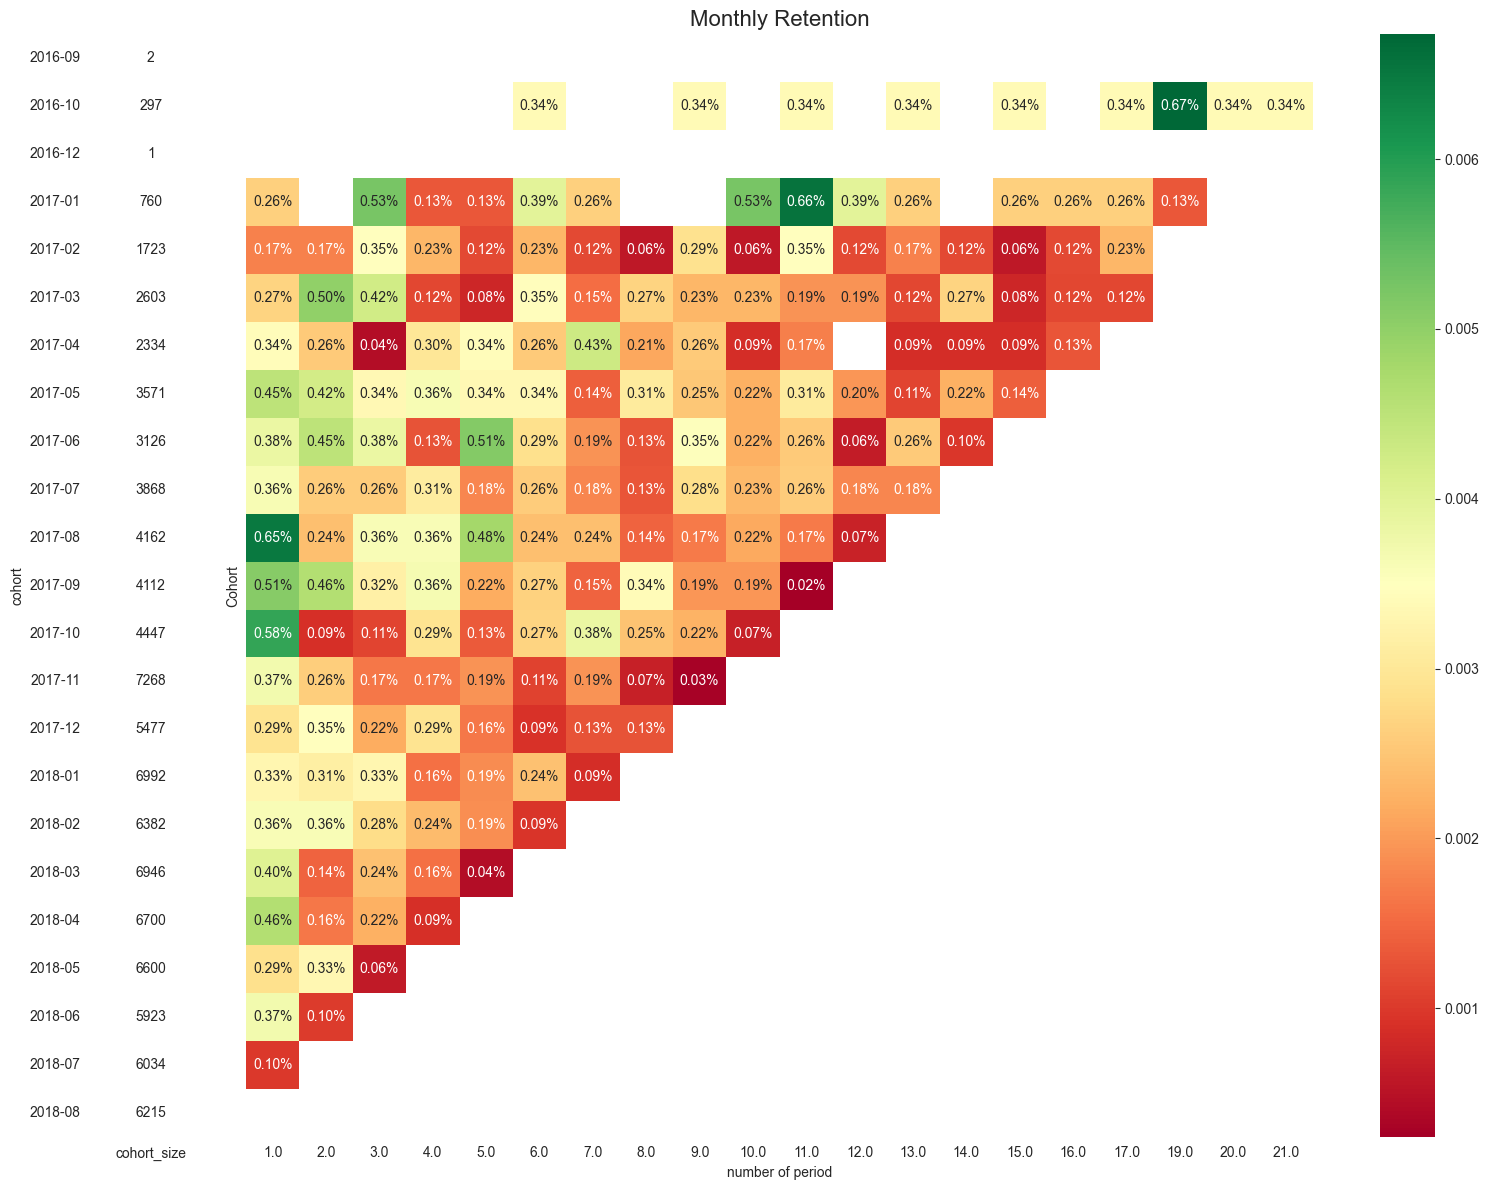

In [48]:
# Строим тепловую карту когортного анализа (вариант из урока)
with sns.axes_style("white"):
    fig, ax = plt.subplots(1, 2, figsize=(16, 12), sharey=True,
                           gridspec_kw={'width_ratios': [1, 11]})

    # убираем столбец с 100%
    heatmap_df = retention_matrix.iloc[:, 1:]

    sns.heatmap(
        heatmap_df,
        mask=heatmap_df.isnull(),     
        annot=True,
        fmt='.2%',
        cmap='RdYlGn',
        ax=ax[1]
    )
    ax[1].set_title('Monthly Retention', fontsize=16)
    ax[1].set(xlabel='number of period', ylabel='Cohort')

    # pазмеры когорт
    cohort_size_df = pd.DataFrame(cohort_size).rename(columns={0: 'cohort_size'})
    sns.heatmap(cohort_size_df,
                annot=True, cbar=False, fmt='g',
                cmap=mcolors.ListedColormap(['white']),
                ax=ax[0])

    fig.tight_layout()
    plt.show()

## Задача 2. Определить, существует ли product/market fit у маркетплейса.

Оценить наличие product/market fit у данного продукта с помощью когортного анализа, полученного на предыдущем шаге.
Пояснить свою позицию и сформулировать, на чём маркетплейс должен сконцентрироваться в ближайшее время. Если PMF есть, то в какую сторону лучше развивать продукт дальше? Если PMF нет, то какие причины могут быть у этого?
Подкрепить свои выводы релевантной визуализацией, удобной для восприятия.

In [49]:
cohort_size_df.head()

,cohort_size
cohort,
2016-09,2.0
2016-10,297.0
2016-12,1.0
2017-01,760.0
2017-02,1723.0


Состояние product/market fit наступает, когда у продукта есть регулярные пользователи. То есть для PMF нужен устойчивый retention, не равный 0.

In [50]:
retention_matrix.describe()

period_number_month,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,19.0,20.0,21.0
count,23.0,19.000000,17.000000,17.000000,16.000000,15.000000,15.000000,13.000000,11.000000,11.000000,...,10.000000,7.000000,8.000000,5.000000,6.000000,4.000000,4.000000,2.000000,1.000000,1.000000
mean,1.0,0.003665,0.002868,0.002725,0.002310,0.002203,0.002510,0.002038,0.001850,0.002380,...,0.002721,0.001737,0.001905,0.001581,0.001601,0.001558,0.002368,0.004025,0.003367,0.003367
std,0.0,0.001308,0.001268,0.001282,0.000966,0.001380,0.000914,0.001022,0.000959,0.000891,...,0.001664,0.001121,0.000879,0.000829,0.001141,0.000719,0.000921,0.003831,NaN,NaN
min,1.0,0.000994,0.000899,0.000428,0.000896,0.000432,0.000913,0.000858,0.000580,0.000275,...,0.000243,0.000640,0.000857,0.000857,0.000580,0.001153,0.001153,0.001316,0.003367,0.003367
25%,1.0,0.002900,0.001741,0.002191,0.001509,0.001333,0.002362,0.001400,0.001279,0.002097,...,0.001766,0.000941,0.001144,0.000960,0.000790,0.001159,0.002029,0.002670,0.003367,0.003367
50%,1.0,0.003619,0.002614,0.002820,0.002336,0.001859,0.002585,0.001810,0.001442,0.002520,...,0.002572,0.001810,0.001775,0.001161,0.001129,0.001223,0.002477,0.004025,0.003367,0.003367
75%,1.0,0.004256,0.003604,0.003482,0.003025,0.002775,0.003120,0.002403,0.002581,0.002873,...,0.003295,0.001941,0.002577,0.002240,0.002324,0.001622,0.002815,0.005379,0.003367,0.003367
max,1.0,0.006487,0.004994,0.005263,0.003648,0.005118,0.003947,0.004284,0.003405,0.003519,...,0.006579,0.003947,0.003367,0.002689,0.003367,0.002632,0.003367,0.006734,0.003367,0.003367


Судя по матрице retention max по каждому месяцу меньше 1%, что показывает устройчивость значения практически на уровне 0.
PMF у маркетплейса нет

Построим зависимость медианного ретеншт по всем когортам  от месяца. 

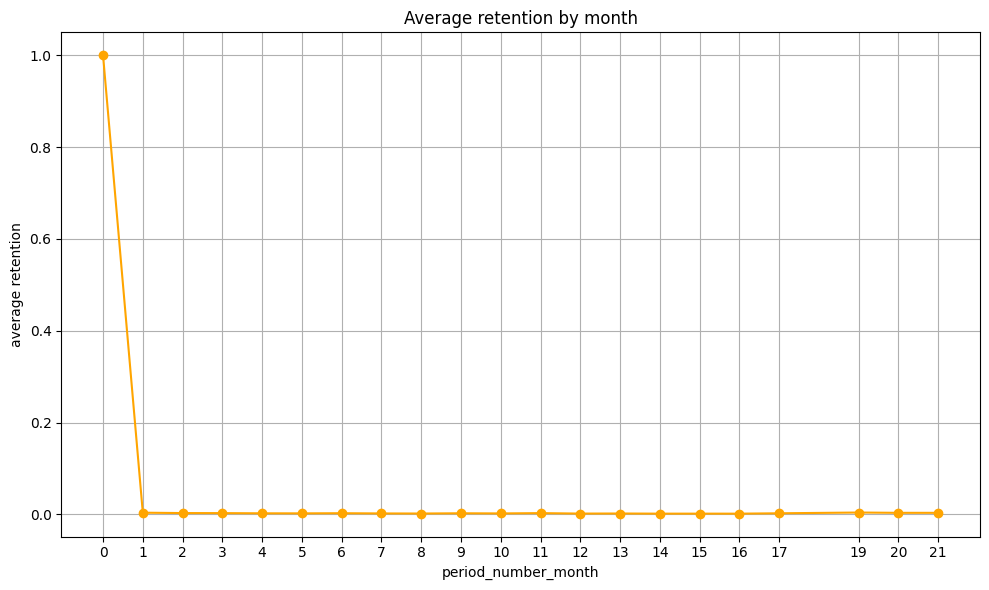

In [51]:
monthly_means = retention_matrix.mean(skipna=True)

# Строим график
plt.figure(figsize=(10, 6))
plt.plot(monthly_means.index, monthly_means.values, marker='o', color='orange')
plt.title("Average retention by month")
plt.xlabel("period_number_month")
plt.ylabel("average retention")
plt.grid(True)
plt.xticks(monthly_means.index)
plt.tight_layout()
plt.show()

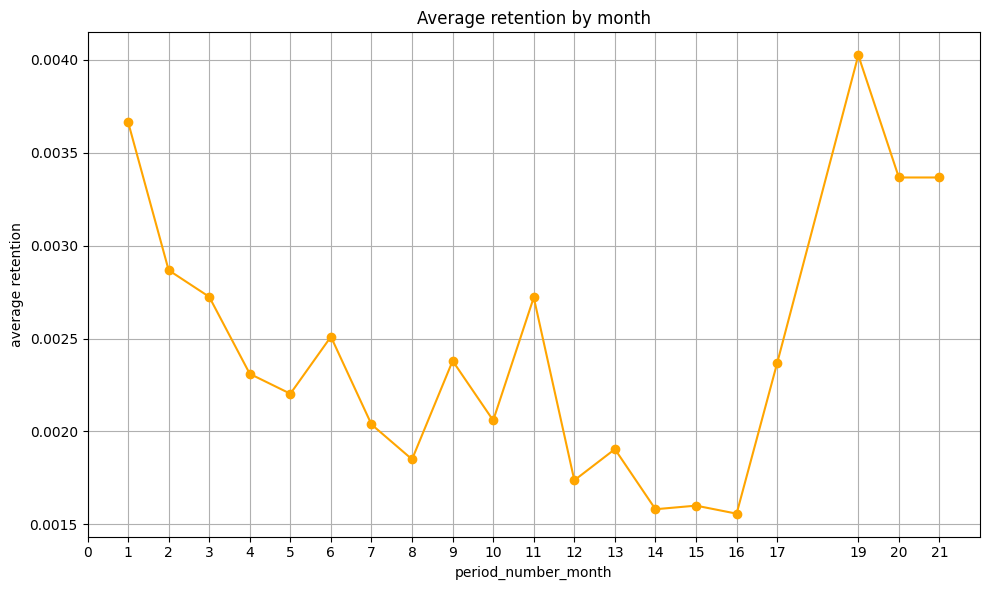

In [52]:
monthly_means_without_first = retention_matrix.iloc[:, 1:].mean(skipna=True)
monthly_means_without_first
# Строим график всех периодов кроме нулевого периода
plt.figure(figsize=(10, 6))
plt.plot(monthly_means_without_first.index, monthly_means_without_first.values, marker='o', color='orange')
plt.title("Average retention by month")
plt.xlabel("period_number_month")
plt.ylabel("average retention")
plt.grid(True)
plt.xticks(monthly_means.index)
plt.tight_layout()
plt.show() 


Видим, что Retention сначала падает с 0.37% до 0.22% в течение первых 4 месяцев, потом немного растет, но на 12-16 месяц снова падает до правктически 0%.
18 когорты нет, на 19 резкий подъем ретенш. Но все равно это подъем на уровень чуть выше, чем в первый месяц использования продукта. Вероятно, в этот месяц старым пользователям пришли пуши с напоминанием сделать заказ или с какой-то акцией, что смотивировало их на покупку. 
Но в общем по графикам виден отток покупателей.


________________________________________________________________________________________________________________

Поисследуем интервалы:
- создание заказа - подтверждение
- подтверждение - передача в курьерскую службу (время сборки)
- передача в службу - доставка

In [53]:
paid_non_canceled_orders[["order_status", "order_purchase_timestamp", 
                          "order_approved_at", "order_delivered_carrier_date",
                          "order_delivered_customer_date", "order_estimated_delivery_date",
                          "customer_state"]].head()

,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_state
0,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,SP
1,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,BA
2,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,GO
3,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,RN
4,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,SP


- order_purchase_timestamp — время создания заказа
- order_approved_at — время подтверждения оплаты заказа
- order_delivered_carrier_date — время передачи заказа в логистическую службу
- order_delivered_customer_date — время доставки заказа
- order_estimated_delivery_date — обещанная дата доставки

In [54]:
# cреднее время доставки заказа
orders["delivery_days"] = orders.order_delivered_customer_date.dt.to_period('D').astype(int) \
                - orders.order_delivered_carrier_date.dt.to_period('D').astype(int)

# cреднее время от создания заказа до апрува
orders["create_to_approve_days"] = orders.order_approved_at.dt.to_period('D').astype(int) \
                - orders.order_purchase_timestamp.dt.to_period('D').astype(int)

# cреднее время сборки заказа (от оплаты до передачи в курьерскую службу)
orders["approve_to_carries_days"] = orders.order_delivered_carrier_date .dt.to_period('D').astype(int) \
                - orders.order_approved_at.dt.to_period('D').astype(int)

# среднее время от создания заказа до доставки
orders["create_to_delivery"] = orders.order_delivered_customer_date .dt.to_period('D').astype(int) \
                - orders.order_purchase_timestamp.dt.to_period('D').astype(int)


In [55]:
orders[["create_to_approve_days", "approve_to_carries_days", "delivery_days", "create_to_delivery" ]].describe()

,create_to_approve_days,approve_to_carries_days,delivery_days,create_to_delivery
count,9.944100e+04,9.944100e+04,9.944100e+04,9.944100e+04
mean,1.484035e+16,1.505368e+17,1.096331e+17,2.750103e+17
std,3.696745e+17,1.178882e+18,1.000444e+18,1.568731e+18
min,0.000000e+00,-9.223372e+18,-9.223372e+18,0.000000e+00
25%,0.000000e+00,1.000000e+00,4.000000e+00,7.000000e+00
50%,0.000000e+00,2.000000e+00,7.000000e+00,1.000000e+01
75%,1.000000e+00,4.000000e+00,1.200000e+01,1.600000e+01
max,9.223372e+18,9.223372e+18,9.223372e+18,9.223372e+18


- Медианная доставка (именно в пути) занимает 7 дней
- Медианна время до подтверждения заказа - 0 дней, то есть подтвержается в тот же день, среднее полдня, что тоже в принципе ок
- Медианное время сборки 2 дня
- Медианное от создания заказа до доставки - 10 дней

Видим выбросы в approve_to_carries_days и delivery_days и (странные max/min знаечния, скорее всего из-за Nan дат) => оставим только данные с датами

In [56]:
df1 = orders.query('order_delivered_carrier_date.isna() != True and \
                                order_delivered_customer_date.isna() != True and \
                                order_approved_at.isna() != True and \
                                order_purchase_timestamp.isna() != True')

In [57]:
df1[["create_to_approve_days", "approve_to_carries_days", "delivery_days", "create_to_delivery" ]].describe()

,create_to_approve_days,approve_to_carries_days,delivery_days,create_to_delivery
count,96461.000000,96461.000000,96461.000000,96461.000000
mean,0.512777,2.701123,9.282892,12.496791
std,0.963546,3.556212,8.777810,9.555298
min,0.000000,-171.000000,-16.000000,0.000000
25%,0.000000,1.000000,4.000000,7.000000
50%,0.000000,2.000000,7.000000,10.000000
75%,1.000000,3.000000,12.000000,16.000000
max,31.000000,126.000000,205.000000,210.000000


Видим, что медианные значения особо не поменялись, выбросы ушли, получились более явные мин/макс значения

In [58]:
df2 = df1.query('approve_to_carries_days < 0')
df2[["order_id", "order_approved_at", "order_delivered_carrier_date"]]

,order_id,order_approved_at,order_delivered_carrier_date
15,dcb36b511fcac050b97cd5c05de84dc3,2018-06-12 23:31:02,2018-06-11 14:54:00
64,688052146432ef8253587b930b01a06d,2018-04-24 18:25:22,2018-04-23 19:19:14
199,58d4c4747ee059eeeb865b349b41f53a,2018-07-26 23:31:53,2018-07-24 12:57:00
415,56a4ac10a4a8f2ba7693523bb439eede,2018-07-27 23:31:09,2018-07-24 14:03:00
483,4df92d82d79c3b52c7138679fa9b07fc,2018-07-29 23:30:52,2018-07-26 14:46:00
...,...,...,...
98884,67884ec2877808808c25211dce58689b,2017-05-12 21:33:56,2017-05-10 11:43:58
99023,fba0d18dccd0e4e88943d84a0f5aa448,2018-04-24 18:33:58,2018-04-23 23:12:12
99230,78008d03bd8ef7fcf1568728b316553c,2018-07-05 16:32:52,2018-07-03 12:57:00
99266,76a948cd55bf22799753720d4545dd2d,2018-02-04 23:31:46,2018-01-31 18:11:58


Видим, что есть 674 заказа, у которых дата передачи в курьерскую службу раньше чем подтверждение заказа 
Это может указывать на проблемы с управлением данными в компании и несогласованность процессов с курьерской службой

In [59]:
df3 = df1.query('delivery_days < 0')
df3[["order_id", "order_delivered_carrier_date", "order_delivered_customer_date"]]

,order_id,order_delivered_carrier_date,order_delivered_customer_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,2017-07-28 16:57:58,2017-07-25 19:32:56
9553,383aa8b2724fe452d9ccd9934a8c628b,2017-07-07 17:22:41,2017-07-06 14:27:51
13487,cb1134f9010d242e9515ad1c78ec0c39,2017-07-20 19:22:02,2017-07-19 14:13:28
14474,dceb62e8fa94b46006c9554fed743df0,2017-08-01 18:23:30,2017-07-26 18:09:10
21338,8c78d01de3a9009e23d6877a7cc9be20,2016-10-26 11:41:53,2016-10-25 17:51:46
22520,b27af682321527a6349f1761eb3f360c,2017-06-27 14:51:54,2017-06-26 15:45:35
25646,e37f11cae9985ca58f0b56f268720537,2017-08-01 18:17:47,2017-07-31 17:49:56
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,2017-08-09 18:18:43,2017-08-01 21:13:01
34939,c1e2bf2b7dd3309f2f5356c6b63968fa,2017-03-02 17:34:26,2017-02-14 15:15:57
41636,b866af202be0692766081310cd4085e1,2017-02-20 02:32:08,2017-02-15 03:53:46


In [60]:
df3.shape

(20, 12)

Аналогично, есть 20 заказов, у которых order_delivered_customer_date >order_delivered_carrier_date, то есть заказы уже доставлены, а по дате только переданы в курьерскую службу

In [61]:
df_with_days = df1.query('approve_to_carries_days >=  0 and delivery_days  >= 0')
df_with_days[["create_to_approve_days", "approve_to_carries_days", "delivery_days", "create_to_delivery" ]].describe()

,create_to_approve_days,approve_to_carries_days,delivery_days,create_to_delivery
count,95767.000000,95767.000000,95767.000000,95767.000000
mean,0.492821,2.731776,9.299769,12.524366
std,0.922055,3.500706,8.770102,9.566489
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,4.000000,7.000000
50%,0.000000,2.000000,7.000000,10.000000
75%,1.000000,3.000000,12.000000,16.000000
max,31.000000,126.000000,205.000000,210.000000


Получили данные по интервалам длительности за исключением выбросов

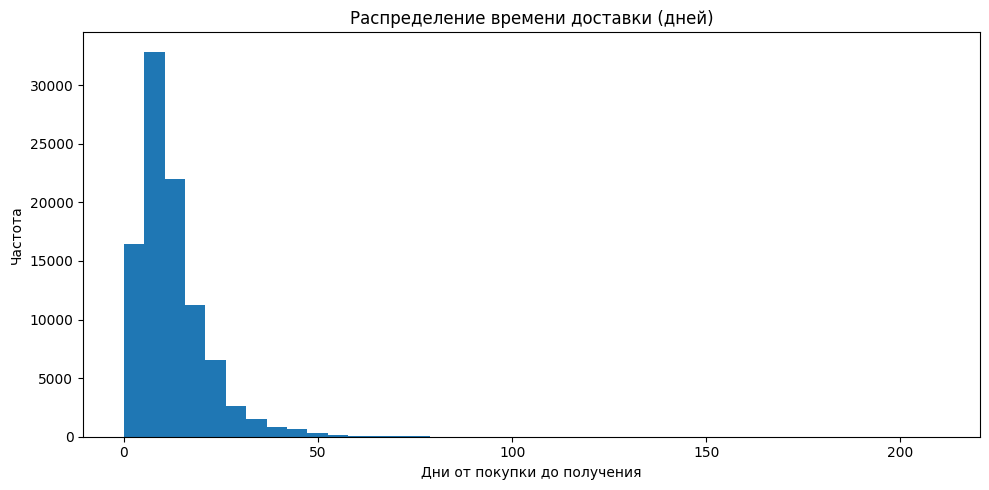

In [62]:
plt.figure(figsize=(10, 5))
plt.hist(df_with_days['create_to_delivery'], bins=40)
plt.title('Распределение времени доставки (дней)')
plt.xlabel('Дни от покупки до получения')
plt.ylabel('Частота')
plt.tight_layout()
plt.show()

In [63]:
df_with_days['create_to_delivery'].quantile(q=0.9)

np.float64(23.0)

75-й персентиль составляет 16 дней от времени создания заказа до доставки, 
90‑й перцентиль -  23 дня.	
Доставка слишком долгая для доставки в пределах одной страны (судя по штатам доставка в пределах одной страны).
Гипотеза: нужно увеличивать скорость доставки (делать какие-то экспресс варинаты доставок для крупных штатов, больше ближних складов для доставок).

________________________________________________________________________________________________________________

Посмотрим на время доставки заказа в зависимости от штата.

In [64]:
df_with_days_merged_customers=df_with_days.merge(right=customers, how='left', on='customer_id')
df_with_days_merged_customers.groupby(["customer_state"]).agg(create_to_delivery=('create_to_delivery', 'mean'))\
                                                .sort_values('create_to_delivery', ascending=False)

,create_to_delivery
customer_state,
RR,29.341463
AP,27.179104
AM,26.358621
AL,24.327411
PA,23.758253
MA,21.554149
SE,21.462687
CE,21.268562
AC,20.911392


В топе по длительности доставки находятся штаты, располоденные на севере и северо-востоке страны. 
Чтобы уменьшить время доставки возможно стоит увеличить кол-во складов для доставки в этих районах.

In [65]:
df_with_days.groupby('order_status').agg(count=('order_id', 'nunique'))

,count
order_status,
canceled,6
delivered,95761


В основном если мы рассматривает только заказы, у которых не было проблем с указанием дат в ходе доставки (даты отгрузки/предполагемой доставки/доставки), это это все доставленные заказы

________________________________________________________________________________________________________________

Посмотрим, есть ли разница между заявленной датой доставки заказа и реальной датой доставки заказа. Будем учитывать только доставленные заказы и заказы, у которых есть дата order_estimated_delivery_date и order_delivered_customer_date

In [66]:
diff_estimate = df_with_days_merged_customers.query('order_delivered_carrier_date.isna() != True and \
                              order_delivered_customer_date.isna() != True and \
                              order_estimated_delivery_date > order_delivered_customer_date and \
                              order_status =="delivered" ')
# Доставленные заказы со всеми помежуточными датами доставки (и следовательно разницей в днях между этапами доставки)
delivered = df_with_days_merged_customers.query('order_delivered_carrier_date.isna() != True and \
                              order_delivered_customer_date.isna() != True and \
                              order_status =="delivered" ')
print(delivered.shape)
print(diff_estimate.shape)
print(diff_estimate.shape[0]/delivered.shape[0])

(95761, 16)
(87955, 16)
0.9184845605204625


In [67]:
df_with_days_merged_customers.isnull().sum()

order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
delivery_days                    0
create_to_approve_days           0
approve_to_carries_days          0
create_to_delivery               0
customer_unique_id               0
customer_zip_code_prefix         0
customer_city                    0
customer_state                   0
dtype: int64

In [68]:
df1.isnull().sum()

order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
delivery_days                    0
create_to_approve_days           0
approve_to_carries_days          0
create_to_delivery               0
dtype: int64

In [69]:
(diff_estimate.order_estimated_delivery_date - diff_estimate.order_delivered_customer_date).describe()

count                         87955
mean     12 days 23:50:06.523597294
std       7 days 09:01:06.809571158
min                 0 days 00:00:05
25%                 7 days 23:18:45
50%                12 days 07:25:17
75%         17 days 00:31:14.500000
max               146 days 00:23:13
dtype: object

Почти 91,9% заказов доставляются раньше обещанной даты доставки, что с одной стороны хорошо,  
но с другой стороны это может указывать на проблемы c моделью предсказания даты доставки, а пользователям обычно важно знать точную дату доставки заказа

Медианна разница между ожидаемой датой доставки и фактической составляет 12 дней, что очень много!

________________________________________________________________________________________________________________

Посмотрим на кол-во уникальных клиентов, которые совершали заказы за все время и на кол-во клиентов, которые совершили РОВНО одну покупку

In [70]:
uniq_1 = paid_non_canceled_orders.groupby('customer_unique_id').agg(cnt=('customer_id', 'nunique'))\
                                                      .query('cnt == 1')
print(uniq_1.shape)

(92621, 1)


In [71]:
print(paid_non_canceled_orders.customer_unique_id.nunique())
print(uniq_1.shape[0]/paid_non_canceled_orders.customer_unique_id.nunique())

95543
0.96941691175701


97% полльзователей совершили ровно одну покупку => продукт не создаёт привычку и им не пользуются

In [72]:
paid_non_canceled_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


Выше мы получали информацию, что в северные штаты доставляется меньше заказов. Составим список северных штатов и поищем закономерности. Смотрю на доставленные заказы и на заказы, в которых есть дни, потому что хочу найти по ним различия - датасет delivered

In [73]:
north_states = ["RR", "AP", "AM", "AL", "PA", "MA", "CE", "AC", "PI", "RN"]

In [74]:
delivered.shape        

(95761, 16)

In [75]:
uniq_more_1 = delivered.groupby('customer_unique_id').agg(cnt=('customer_id', 'nunique'))\
                                                      .query('cnt > 1')
print(uniq_more_1.shape)   #совершили и доставили больше чем 1 покупку!! 

(2772, 1)


In [76]:
purchase_north = delivered[delivered.customer_state.isin(north_states) == True]
print(len(purchase_north))

4590


In [77]:
purchase_not_north =delivered[delivered.customer_state.isin(north_states) == False]
print(len(purchase_not_north))
print(len(purchase_north)/len(purchase_not_north))

91171
0.050344956181241844


Большинство покупок (95%) было совершено НЕ в северных штатах

In [78]:
north_more1_purchase = purchase_north.groupby(['customer_state','customer_unique_id'], as_index=False)\
                                            .agg(cnt=('order_id', 'nunique'))\
                                            .query('cnt > 1')\
                                            .sort_values('cnt', ascending=False)
north_more1_purchase 

,customer_state,customer_unique_id,cnt
2049,MA,35ecdf6858edc6427223b64804cf028e,5
554,AM,a239b8e2fbce33780f1f1912e2ee5275,4
3892,PI,cfa69922f9968e0e6271647abda09b09,3
3540,PI,0cc2ee1112a11a1094eff52fa2e87150,3
1657,CE,c7c19110042036e6266adc998cbf1289,3
...,...,...,...
1239,CE,75bbb6b481a1df1689bb769e63ec3acb,2
1160,CE,67fcfe4915b93624867d350b8191ff7b,2
1157,CE,67bddde1844b238fe25995cde1612b4e,2
1082,CE,589211c7448e6c3b58b0ba98ce089ee7,2


In [79]:
not_north_more1_purchase = purchase_not_north.groupby(['customer_state','customer_unique_id'], as_index=False)\
                                            .agg(cnt=('order_id', 'nunique'))\
                                            .query('cnt > 1')\
                                            .sort_values('cnt', ascending=False)
not_north_more1_purchase

,customer_state,customer_unique_id,cnt
70546,SP,8d50f5eadf50201ccdcedfb9e2ac8455,15
58649,SP,3e43e6105506432c953e165fb2acf44c,9
64470,SP,6469f99c1f9dfae7733b25662e7f1782,7
23101,PE,ca77025e7201e3b30c44b472ff346268,7
10185,MG,1b6c7548a2a1f9037c1fd3ddfed95f33,7
...,...,...,...
32001,RJ,5416f8ad5bc33953624084ebc8738307,2
32062,RJ,5568fb2b583235812ed08eb9587d0465,2
32092,RJ,56238e115fd05d88a5e9ae565b8c2dbb,2
32093,RJ,562b3bca5a8903b7451462b6e7aa6082,2


In [80]:
print(len(north_more1_purchase) * 100/len(uniq_more_1))

3.427128427128427


- Видим, что максимум было 5 покупок для северных штатов из штата MA для юзера 35ecdf6858edc6427223b64804cf028e. 
- только 3,5% ВСЕХ пользователей кто повторную покупку совершил - из северных штатов 


In [81]:
# посмотрим конверсию в повторную покупку из северных штатов
north_1_and_more_purchase = purchase_north.groupby(['customer_state','customer_unique_id'], as_index=False)\
                                            .agg(cnt=('order_id', 'nunique'))\
                                            .query('cnt >= 1')\
                                            .sort_values('cnt', ascending=False)
len(north_1_and_more_purchase)     # 4485

4485

In [82]:
print(len(north_more1_purchase)/len(north_1_and_more_purchase))

0.021181716833890748


In [83]:
# посмотрим конверсию в повторную покупку из НЕ северных штатов
not_north_1_and_more_purchase = purchase_not_north.groupby(['customer_state','customer_unique_id'], as_index=False)\
                                            .agg(cnt=('order_id', 'nunique'))\
                                            .query('cnt >= 1')\
                                            .sort_values('cnt', ascending=False)
len(not_north_1_and_more_purchase )     # 88225

88225

In [84]:
print(len(not_north_more1_purchase)/len(not_north_1_and_more_purchase))

0.02996882969679796


Конверсия в повторную покупку различается в 1,4 раза => клиенты не из северо и северо-восточных штатов активнее возвращаются за повторным заказом.

Посмотрим на разницу в днях доставки между северными и не северными штатами

In [85]:
purchase_north["create_to_delivery"].describe()

count    4590.000000
mean       21.992375
std        13.390189
min         1.000000
25%        14.000000
50%        19.000000
75%        27.000000
max       196.000000
Name: create_to_delivery, dtype: float64

In [86]:
purchase_not_north["create_to_delivery"].describe()

count    91171.000000
mean        12.047186
std          9.074785
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        210.000000
Name: create_to_delivery, dtype: float64

Медианное время доставки в северных штатах и не в северных различается на 9 дней! Это почти в два раза

Разница между 90-ми перцинтилями тоже довольно существенная - 14 дней!

In [87]:
purchase_north['create_to_delivery'].quantile(q=0.9)

np.float64(36.0)

In [88]:
purchase_not_north['create_to_delivery'].quantile(q=0.9)

np.float64(22.0)

________________________________________________________________________________________________________________

Посмотрим на связь товаров и доставленных заказов (доставленные - будет датасет paid_delivered_orders, так как мне не нужно условие на наличие дат, чтобы посчитать разницу между этапами доставки)

In [89]:
items.head(2)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93


In [90]:
paid_delivered_orders.head(2)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA


In [91]:
paid_delivered_orders_with_items = paid_delivered_orders.merge(right=items, how='left', on='order_id')

In [92]:
paid_delivered_orders_with_items.head(2)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76


In [93]:
paid_delivered_orders_with_items.order_id.nunique()

96464

In [94]:
paid_delivered_orders.order_id.nunique()

96464

Посмотрим сколько заказов содержит 1 товар, а сколько заказов содержит 2 и больше товаров

In [95]:
paid_delivered_orders_with_items.groupby('order_id', as_index = False).agg(products_cnt=('product_id', 'count'))\
            .query('products_cnt > 1')

,order_id,products_cnt
13,0008288aa423d2a3f00fcb17cd7d8719,2
31,00143d0f86d6fbd9f9b38ab440ac16f5,3
39,001ab0a7578dd66cd4b0a71f5b6e1e41,3
43,001d8f0e34a38c37f7dba2a37d4eba8b,2
69,002c9def9c9b951b1bec6d50753c9891,2
...,...,...
96401,ffd84ab39cd5e873d8dba24342e65c01,2
96424,ffe4b41e99d39f0b837a239110260530,2
96435,ffecd5a79a0084f6a592288c67e3c298,3
96452,fff8287bbae429a99bb7e8c21d151c41,2


In [96]:
paid_delivered_orders_with_items.groupby('order_id', as_index = False).agg(products_cnt=('product_id', 'count'))\
            .query('products_cnt == 1')

,order_id,products_cnt
0,00010242fe8c5a6d1ba2dd792cb16214,1
1,00018f77f2f0320c557190d7a144bdd3,1
2,000229ec398224ef6ca0657da4fc703e,1
3,00024acbcdf0a6daa1e931b038114c75,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1
...,...,...
96459,fffc94f6ce00a00581880bf54a75a037,1
96460,fffcd46ef2263f404302a634eb57f7eb,1
96461,fffce4705a9662cd70adb13d4a31832d,1
96462,fffe18544ffabc95dfada21779c9644f,1


### Задача 3

Определить 5 основных метрик, на которых продакт может сконцентрироваться, чтобы максимизировать прибыль компании.

- Первая метрика должна отражать рост объёма продаж маркетплейса.
- Вторая — показывать объем аудитории, которой продукт доставляет ценность.
- Третья — отражать заинтересованность новых клиентов в продукте (даже если вы не можете посчитать ее на имеющихся у вас данных).
- Четвёртая — отражать вовлеченность клиента в продолжение использования продукта.
- Пятая — отражать денежное выражение вовлеченности клиента.

##### 3.1 Рост объёма продаж маркетплейса

Рост объема продаж покажет метрика GMV (Gross Merchandise Volume, общая стоимость проданных товаров)

Будем учитывать заказы, за которые маркетплейс получил деньги, то есть оплаченные и доставленные заказы - paid_delivered_orders.

Смержить все три таблицы сразу в 1
Будем смотреть динамику продаж по месяцам

In [97]:
# GMV для каждого заказа = сумма цен его позиций
gmv_per_order = items.groupby('order_id', as_index=False)['price'].sum()                        
gmv_per_order.head()          

,order_id,price
0,00010242fe8c5a6d1ba2dd792cb16214,58.90
1,00018f77f2f0320c557190d7a144bdd3,239.90
2,000229ec398224ef6ca0657da4fc703e,199.00
3,00024acbcdf0a6daa1e931b038114c75,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90


In [98]:
task3_1 = paid_delivered_orders.copy()
task3_1 = task3_1.merge(gmv_per_order, on='order_id', how='left')
task3_1.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,price
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,19.90


In [99]:
task3_1['order_month'] = (pd
    .to_datetime(task3_1['order_purchase_timestamp'])     
    .dt.to_period('M')
    .dt.to_timestamp())       

In [100]:
task3_1.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,price,order_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,29.99,2017-10-01
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,118.70,2018-07-01
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,159.90,2018-08-01
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,45.00,2017-11-01
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,19.90,2018-02-01


In [101]:
# GMV по месяцам
gmv_month = task3_1.groupby('order_month').agg({'price': 'sum'})

In [102]:
gmv_month.head()

,price
order_month,
2016-09-01,134.97
2016-10-01,40325.11
2016-12-01,10.90
2017-01-01,111712.47
2017-02-01,232638.86


In [103]:
gmv_month.head(23)

,price
order_month,
2016-09-01,134.97
2016-10-01,40325.11
2016-12-01,10.90
2017-01-01,111712.47
2017-02-01,232638.86
2017-03-01,359198.85
2017-04-01,340669.68
2017-05-01,489338.25
2017-06-01,421923.37


In [104]:
gmv_month.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 23 entries, 2016-09-01 to 2018-08-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   price   23 non-null     float64
dtypes: float64(1)
memory usage: 368.0 bytes


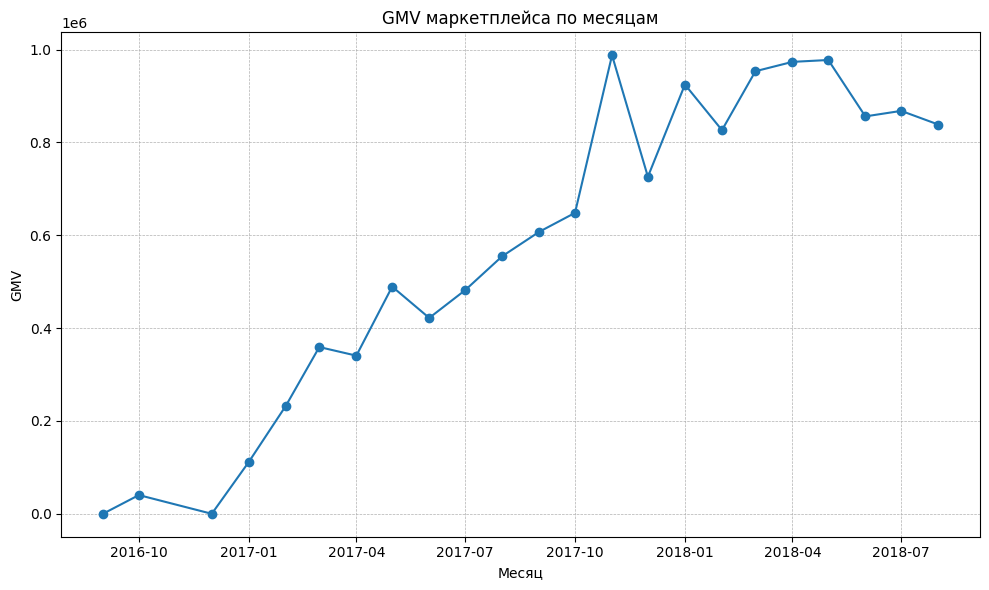

In [105]:
# Рисуем график GMV
plt.figure(figsize=(10, 6))
plt.plot(gmv_month.index, gmv_month.values, marker='o')
plt.title('GMV маркетплейса по месяцам')
plt.xlabel('Месяц')
plt.ylabel('GMV')
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

GMV растет весь 2017 год, достигает пика в октябре = 1 млн, потом выравнивается выравнивается на 0.8млн

##### 3.2 Объем аудитории, которой продукт доставляет ценность

Для оценки аудитории, которой продукт действительно приносит пользу, можно использовать MAU (Monthly Active Users). Построим график MAU  
В качестве меры того, есть ли ценность огт продукта можно считать, была ли произведена оплата за товар и не отменил ли пользователь заказ => будем использовать те же данные, что и в retention (здесь не считаю именно доставленные заказы)

In [106]:
task3_2 = paid_non_canceled_orders.copy()

task3_2['order_month'] = (pd
    .to_datetime(task3_2['order_purchase_timestamp'])     
    .dt.to_period('M')
    .dt.to_timestamp())     

In [107]:
users_month = task3_2.groupby('order_month').agg(cnt=('customer_unique_id', 'nunique'))
users_month.shape

(24, 1)

In [108]:
users_month.head(24)

,cnt
order_month,
2016-09-01,2
2016-10-01,297
2016-12-01,1
2017-01-01,761
2017-02-01,1726
2017-03-01,2609
2017-04-01,2354
2017-05-01,3599
2017-06-01,3166


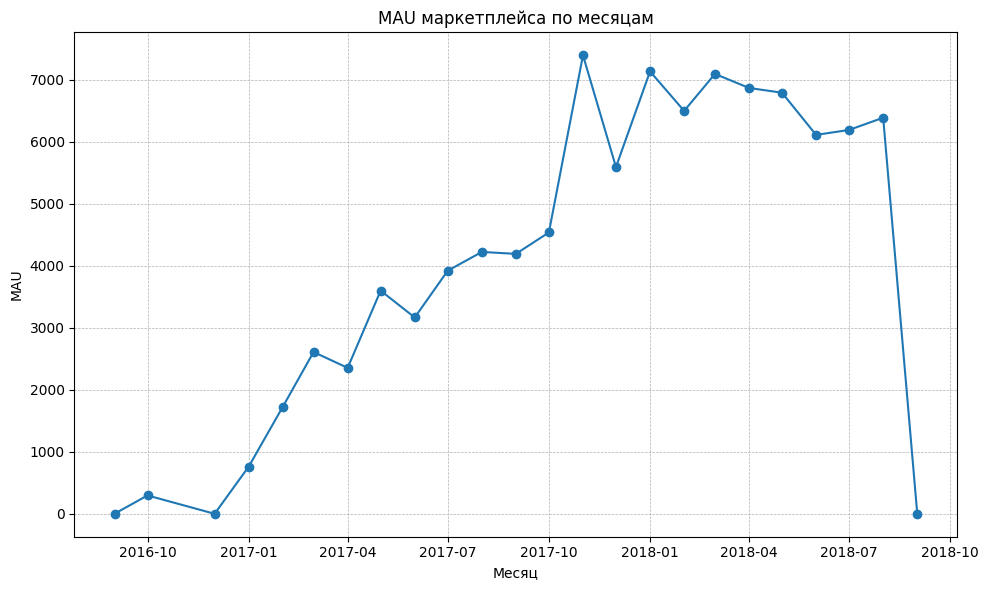

In [109]:
# Рисуем график MAU
plt.figure(figsize=(10, 6))
plt.plot(users_month.index, users_month.values, marker='o')
plt.title('MAU маркетплейса по месяцам')
plt.xlabel('Месяц')
plt.ylabel('MAU')
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

Можно рассмотреть аналогичный график с заказами, которые пользователь совершил и которые доставили - данные из предыдущего шага task3_1

In [110]:
users_month2 = task3_1.groupby('order_month').agg(cnt=('customer_unique_id', 'nunique'))

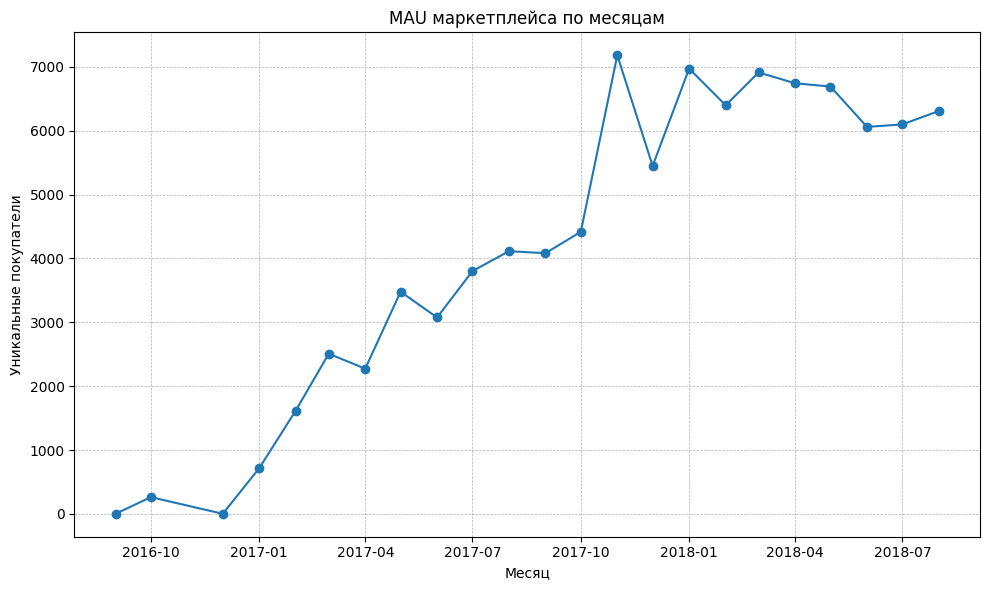

In [111]:
# Рисуем график MAU для delivered
plt.figure(figsize=(10, 6))
plt.plot(users_month2.index, users_month2.values, marker='o')
plt.title('MAU маркетплейса по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Уникальные покупатели')
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

В целом линии похоже, по графику видна в среднем положительная тенденция по росту MAU с каждым месяцем

Однако в сентябре 2018 (2018-09-01) можно увидеть резкий спад MAU

##### 3.3 Метрика, отражающая заинтересованность новых клиентов в продукте (даже если вы не можете посчитать ее на имеющихся у вас данных).

New-User Activation rate - доля новых покупателей, которые совершили оплату ( подтверждили интерес), в первые X дней после первого заказа (допустим, месяц).

New-User Activation rate = новые покупатели (опред периода) , которые через X дней еще раз сделалаи заказ  /
                           все новые покупатели (опред периода)

Можно аналогично посчитать по месяцам и построить график.                  

#####  3.4 Метрика, отражающая вовлеченность клиента в продолжение использования продукта

1) Retention в оформление заказа - считали ранее

2) Можно еще посчитать долю пользователей, которые сделали повторынй заказ (вернулись в приложение) в зависимости от месяца - Repeat Purchase Rate

Берем оплаченные и не отмененные заказы - из расчета метрики 3.2

In [112]:
# месяц первой покупки для каждого пользователя
first_month = task3_2.groupby('customer_unique_id')['order_month'].min()
# флаг: заказ совершен после первого месяца => клиент вернулся
task3_2['returned'] = task3_2.apply(
    lambda row: row['order_month'] > first_month.loc[row['customer_unique_id']],
    axis=1
)

monthly = task3_2.groupby('order_month').agg(
    active_buyers=('customer_unique_id', 'nunique'),
    returning_buyers=('returned', 'sum')
)

monthly['rate'] = (monthly['returning_buyers'] /
                    monthly['active_buyers'] * 100).round(2)

In [113]:
monthly[['active_buyers', 'returning_buyers', 'rate']].head()      

,active_buyers,returning_buyers,rate
order_month,,,
2016-09-01,2,0,0.00
2016-10-01,297,0,0.00
2016-12-01,1,0,0.00
2017-01-01,761,1,0.13
2017-02-01,1726,3,0.17


In [114]:
monthly[['active_buyers', 'returning_buyers', 'rate']].tail()    

,active_buyers,returning_buyers,rate
order_month,,,
2018-05-01,6790,196,2.89
2018-06-01,6110,192,3.14
2018-07-01,6190,158,2.55
2018-08-01,6387,177,2.77
2018-09-01,1,1,100.00


Есть 1 пользователь, который сделал заказ в 2018-09 и вернулся в 2018-10

In [115]:
task3_2.query('order_month == "2018-09-01" and returned == True')\
     .groupby('customer_unique_id').agg(cnt=('order_id', 'nunique'))

/var/folders/ml/prg12jxx45g5ggxvrrn_s7600000gn/T/ipykernel_37057/4278886036.py:1: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  task3_2.query('order_month == "2018-09-01" and returned == True')\


,cnt
customer_unique_id,
ff22e30958c13ffe219db7d711e8f564,1


In [116]:
task3_2.query('customer_unique_id == "ff22e30958c13ffe219db7d711e8f564"')

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_month,returned
22575,6ca46f2b9a1592929647682510800e0e,13bf775a749925a15ef7cc1985b564f1,shipped,2018-08-24 17:02:19,2018-08-24 17:15:10,2018-08-27 15:15:00,NaT,2018-08-29,ff22e30958c13ffe219db7d711e8f564,2989,sao paulo,SP,2018-08-01,False
62360,54282e97f61c23b78330c15b154c867d,4b7decb9b58e2569548b8b4c8e20e8d7,shipped,2018-09-03 09:06:57,2018-09-03 17:40:06,2018-09-04 15:25:00,NaT,2018-09-06,ff22e30958c13ffe219db7d711e8f564,2989,sao paulo,SP,2018-09-01,True


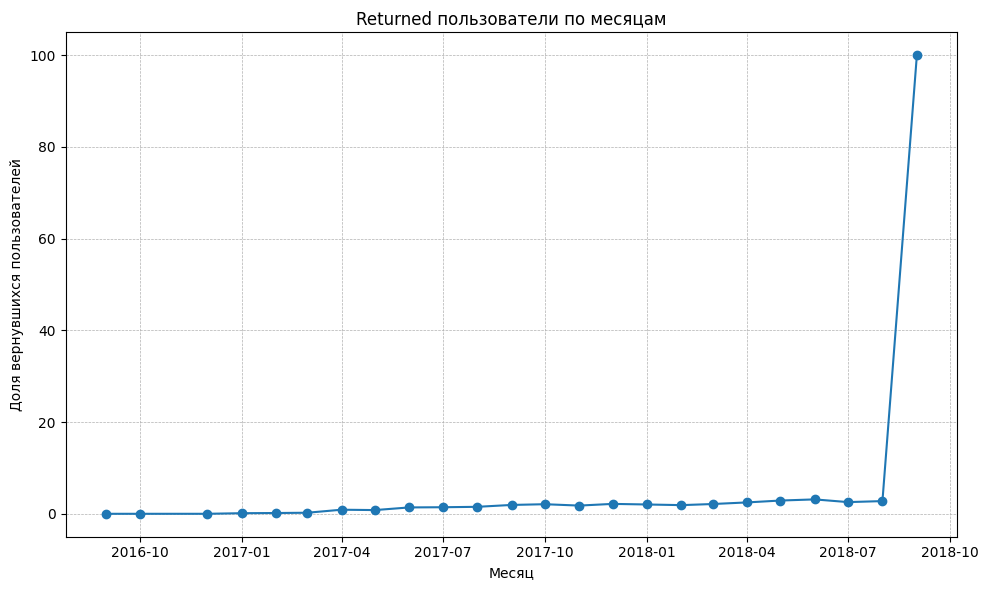

In [117]:
# Рисуем доли пользователей, которые сделали повторынй заказ (вернулись в приложение) в зависимости от месяца
plt.figure(figsize=(10, 6))
plt.plot(monthly.index, monthly.rate, marker='o')
plt.title('Returned пользователи по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Доля вернувшихся пользователей')
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

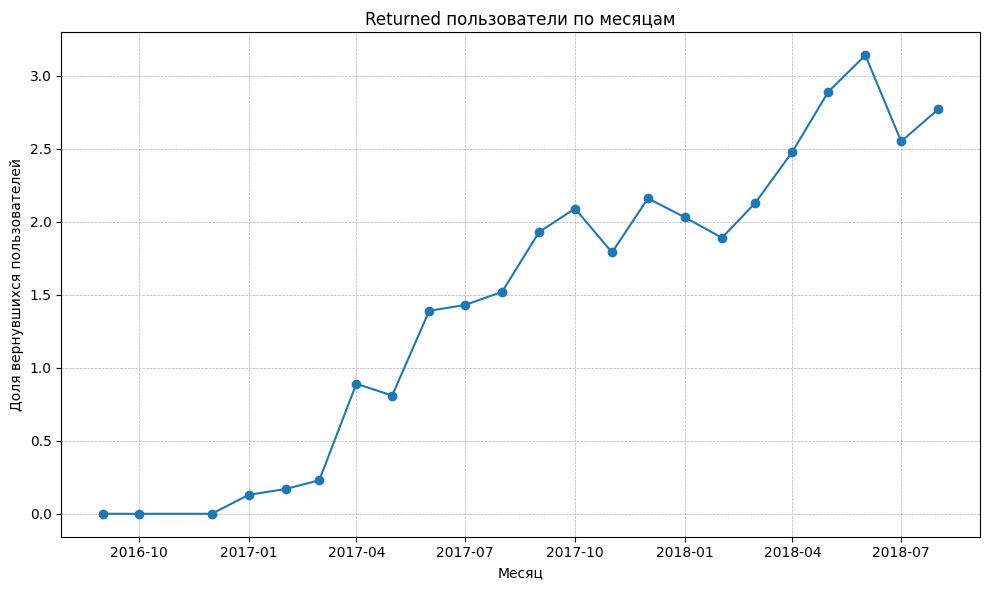

In [118]:
# Рисуем без последнего месяца
without_last_month = monthly.iloc[:23, :]
plt.figure(figsize=(10, 6))
plt.plot(without_last_month.index, without_last_month.rate, marker='o')
plt.title('Returned пользователи по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Доля вернувшихся пользователей')
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

Доля вернувшися пользователей растет с течением месяцев, но все давно довольно низкая, максимум 2,5 - 3%

##### 3.5 Метрика, отражающая денежное выражение вовлеченности клиента

Можно посчитать GMV на активного покупателя

In [119]:
# GMV по месяцам
gmv_by_users = task3_1.groupby('order_month')\
            .agg({'price': 'sum', 'customer_unique_id': 'nunique'})
gmv_by_users['gmv_per_user'] = gmv_by_users["price"]/gmv_by_users["customer_unique_id"]
gmv_by_users.head()

,price,customer_unique_id,gmv_per_user
order_month,,,
2016-09-01,134.97,1,134.970000
2016-10-01,40325.11,262,153.912634
2016-12-01,10.90,1,10.900000
2017-01-01,111712.47,716,156.023003
2017-02-01,232638.86,1618,143.781743


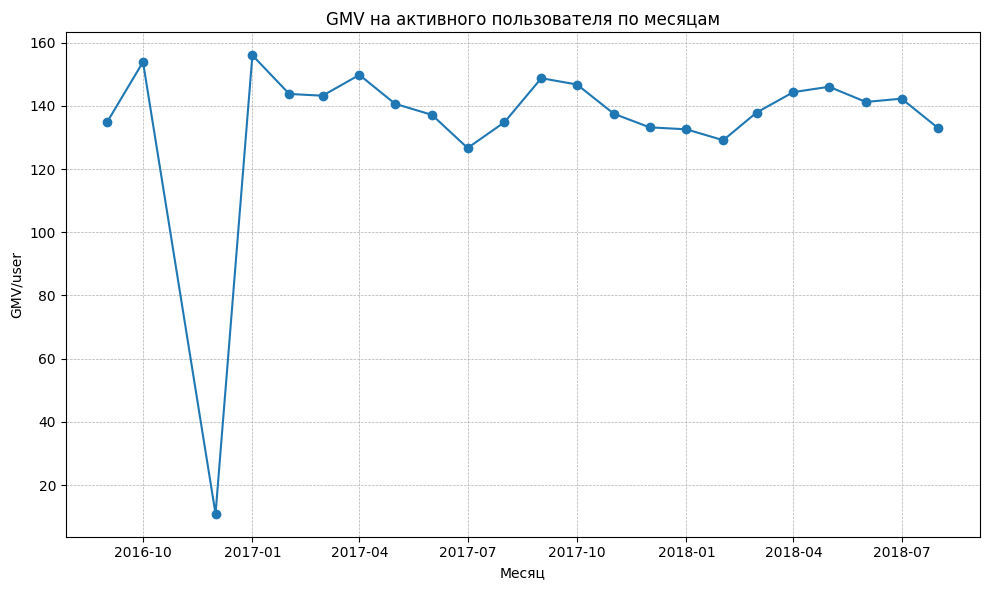

In [120]:

plt.figure(figsize=(10, 6))
plt.plot(gmv_by_users.index, gmv_by_users.gmv_per_user, marker='o')
plt.title('GMV на активного пользователя по месяцам')
plt.xlabel('Месяц')
plt.ylabel('GMV/user')
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

Ежемесячная динамика (см. графики выше):
- GMV рос весь 2017 и достиг пика 1 млн, но далее выравнивается
- MAU следует тому же тренду, показывая примерно 6–7000 активных покупателей к концу выборки.
- Repeat Purchase Rate остаётся низким — всего 2‑3 %: главный рычаг роста.
- GMV per User колеблется в районе 130‑150, в 2016-12 бьл только 1 платящий клиент с маленьким чеком.


Еще мысли: учитывая, что корорта нояьбрьская корогта 2016-11 пропущена, а в декабрьской и сентябрьской было по 1 покупателю, как будто вообще имело смысл рассматривать метрики только начиная с нового года, то есть с когорты 2017-01-01. Возможно, по сентябрб, ноябрю и декабрю не хватате данных и произошел какой-то сбой, что инфа о закзах перестала правильно учитываться. В октябре резко уникальных пользователей стало больше => общий GMV больше. 

### Задача 4. Выбрать одну из 3 основных гипотез с помощью фреймворка ICE.

Посмотрев с продактом на когортный анализ и метрики, вы решили, что нужно изменить продукт. Метрики необходимо срочно повышать. Вместе с командой вы сформулировали 3 гипотезы, в которые вы верите. По каждой гипотезе команда заполнила показатели по Ease, Confidence. Вам нужно заполнить самый важный показатель — Impact. Для этого вам требуется:

Выбрать одну из трёх основных гипотез с помощью фреймворка ICE, которые были сформированы продактом и, кажется, должны улучшить пользовательский опыт в маркетплейсе.

Для расчёта Impact возьмите данные с июня 2017 года. Считайте, что конверсия в повторный заказ равна величине медианного retention 1-го месяца (см. пункт 1 проекта).

Медианый ретенш 1-го месяца был 0.36% для paid_non_canceled_orders => конверсия в повторный заказ 0.36%

##### Гипотеза 1
Если исправим баг в системе процессинга заказов, то клиентам не придётся сталкиваться с проблемой отмены заказа, вследствие чего количество доставленных заказов увеличится. Считаем, что мы таким образом избавимся от всех отмен.

In [121]:
# cчитаем unavailable заказы с с июня 2017 года

In [122]:
paid_non_canceled_orders['order_month'] = (pd
    .to_datetime(paid_non_canceled_orders['order_purchase_timestamp'])     
    .dt.to_period('M')
    .dt.to_timestamp())    

In [123]:
paid_non_canceled_orders_june = paid_non_canceled_orders.query('order_month >= "2017-06-01"')
paid_non_canceled_orders_june.shape

(87242, 13)

In [124]:
# кол-во отмененых заказов, на которые можем повлиять
unavailable = paid_non_canceled_orders_june.query('order_status == "unavailable"') #475 unavailable заказов

# кол-во пользователей, на которые можем повлиять
unavailable_users = unavailable.groupby('customer_unique_id').agg(cnt=('order_id', 'nunique'))  #470

# дополнительные повторные заказы
additional = len(unavailable_users) * 0.0036   #1.67 заказа
print(additional)

1.692


Исправив баг и избежав отмен с причиной unavailable, мы получили бы ≈ 477 дополнительных доставленных заказов за период с июня 2017 года, из которых подавляющее большинство - спасённые первичные покупки, а 2 заказа приходятся на прогнозные ретеншн-повторы.
477 заказов соответсвует Impact 4.

ICE для первой гипотезы: 192
- Impact - 4
- Confidence - 8
- Ease - 6

##### Гипотеза 2
Если сократим время до отгрузки заказа, то клиенты перестанут получать свой заказ с запаздыванием, вследствие чего количество заказов увеличится за счёт повторных заказов. 

In [125]:
 # cколько клиентов получают заказ с запаздыванием?
with_delay = paid_non_canceled_orders_june.query('order_delivered_customer_date > order_estimated_delivery_date')
print(len(with_delay))

with_delay_users = with_delay.groupby('customer_unique_id', as_index=False).agg({'order_id': 'nunique'})
print(len(with_delay_users))

7295
7245


In [126]:
# пользователи, которые получили не опоздывающий заказ сделают заказ еще раз
print(len(with_delay_users) * 0.0036)

26.082


Получим 26  повторных заказов => Impact = 1

ICE для второй гипотезы: 40
- Impact - 1
- Confidence - 10
- Ease - 4

##### Гипотеза 3
Если создадим новый способ оплаты, который будет конвертировать клиентов в повторный заказ, то клиенты не будут испытывать трудности при оформлении заказа, вследствие чего количество заказов увеличится за счёт повторных заказов тех, кто раньше не делал повторный заказ.

In [127]:
# посмотрим на тех, кто сделал только одну покупку за все время, то есть не делали повторных заказов
june_1 = paid_non_canceled_orders_june.groupby('customer_unique_id').agg(cnt=('customer_id', 'nunique'))\
                                                      .query('cnt == 1')
print(len(june_1))


82204


In [128]:
add_users = len(june_1) * 0.0036
print(add_users)

295.9344


Потенциально возможно 296 новых заказов => Impact = 3

ICE для третьей гипотезы: 135
- Impact - 3
- Confidence - 5
- Ease - 9

По фреймворку ICE наибольший приоритет имееет **первая гипотеза** - спасти отмененные заказы.
Она даёт наибольший явный денежный прирост, улучшает пользовательский опыт и минимизирует репутационный ущерб. После её реализации имеет смысл переходить к платёжному улучшению (гипотеза 3) как следующему драйверу роста повторных заказов.

### Задача 5. Сформулировать нужные метрики, на которые ваша гипотеза должна повлиять.

После предыдущего исследования у вас появилась гипотеза, которую можно реализовать для значительного улучшения метрик компании. Вы предложили использовать A/B-тестирование для проверки её эффективности.

Продакт попросил вас:

- Сформулировать метрики, на которые должна повлиять выбранная вами гипотеза.
- Сформулировать хотя бы по одной метрике в категории: целевые, прокси, guardrail и объяснить свой выбор.

1) Целевая метрика - число "спасенных" доставленных заказов.
Она отражает прямой эффект на бизнес: сколько реальных посылок мы “спасли” и довезли клиенту.
Рассчитывается delivered_orders_after - delivered_orders_before 

2) Прокси  - доля  unavailable заказов 
Она должна стремиться к 0. Метрика более быстро сигнализирует, что баг действительно устранили, так как не ждем полнового цикла доставки.

3) Guardrail 
Доля доставленных вовремя заказов
Среднее время доставки

Mы не должны за счет исправления бага и спасенных заказов ухудшить существующие сроки доставки, например, как-то перегрузить логистику.

### Задача 6. Итоги

##### 1.   Формализация проблемы продукта и общие выводы


1) Когортный анализ показал, что медианный retention M1 = 0,36% и к M3-M6 снижается еще до 0.25% и дальше еще ниже.

Явно наблюдается отток клиентов. PMF нет, продуктом практически не пользуются, он не создает привычку. 
Возможно, маркетплейс продает товары не многократного использования (например, какие-то крупногабаритные товары, технику).

2) 97% пользователей совершили ровно одну покупку. То есть потеря пользователей происходит на первой покупке.
- Категории товаров (нет достаточно данных чтобы сделать такой вывод)? 
- Баг в процессенге? Совершил - получил негативный опыт - не вернулся.
Отказы unavailable — до 475 заказов (июнь 2017+) уходят в отмену из-за бага процессинга.

3) 92% заказа доставляются раньше ожидаемой даты доставки, 97% заказов доставлены. 
Медианная разница между ожидаемой датой доставки и фактической составляет 12 дней, что очень много!

Определенно есть проблемы на этапе доставки и при подсчете даты доставки.


4) 484 заказа пользователь отменил ПОСЛЕ оплаты. Почему? Его не устроил срок доставки? Ожидаемая дата доставки? Уменьшение кол-ва 
    подобных ситуаций может быть точкой роста.


5) Анализ доставки/сборки заказов/регионов заказов
- Медианная доставка (именно в пути) занимает 7 дней
- Медианна время до подтверждения заказа - 0 дней, то есть подтвержается в тот же день, среднее полдня, что тоже в принципе ок
- Медианное время сборки 2 дня
- Медианное от создания заказа до доставки - 10 дней

75-й персентиль составляет 16 дней от времени создания заказа до доставки, 90‑й перцентиль -  23 дня.
Доставка слишком долгая для доставки в пределах одной страны (судя по штатам доставка в пределах одной страны). Гипотеза: нужно увеличивать скорость доставки (делать какие-то экспресс варинаты доставок для крупных штатов, больше ближних складов для доставок).

В топе по длительности доставки находятся штаты, расположенные на севере и северо-востоке страны. Чтобы уменьшить время доставки возможно стоит увеличить кол-во складов для доставки в этих районах.
Медианное время доставки в северных штатах и не в северных различается на 9 дней! Это почти в два раза.

Разница между 90-ми перцинтилями тоже довольно существенная - 14 дней.

Есть 674 заказа, у которых дата передачи в курьерскую службу раньше чем подтверждение заказа. Это может указывать на проблемы с управлением данными в компании и несогласованность процессов с курьерской службой.

В общем, маркетплейс больше ориентирован на южные, ю-в, ю-з штаты. 95% покупок совершено жителями не северных штатов. Время доставки в южные и западные штаты в среднем в 2 раза меньше, чем в северные и с-в штаты. Пользователи их этих штатов делают меньше заказов, дольше ждут, меньше делают повторных заказов. Работа с севером и северо-востоком страны может быть точкой роста.

##### Рекомендации по продукту

1) Починить баг с unavailable (гипотеза 1).

2) Ввести новый способ оплаты (гипотеза 3).

3) Ускорение доставки на юге Бразилии (делать какие-то экспресс варинаты доставок для крупных штатов, больше ближних складов для доставок).

4) Работа с клиентами с севера и северо-востока страны (привлечение, удержание, увеличение скорости доставки).

5) Работа над ретеншт маркетплейса (нужен регулярный стимул вернуться, иначе даже «спасённые» клиенты уйдут).

6) Поработать над категориями товаров, добавить более часто заказываемые.

7) Поработать над моделью предсказания ожидаемой даты доставки.